# SHI-100 · Native insula contact coverage

独立的解剖可视化：只显示每个病例的 insula 表面、Hammers 分区边界和 insula 触点。
AIC 触点标红并标注名称，PIC 触点标灰。D152 选择触点更多的 **D152B**；本轮新增 **D157、D158**。

- 数据：2026-10-05 和 2026-10-06 单触点筛查 CSV；无需 bipolar 或 task 信号预处理。
- 参考：`vizpub/fig1.ipynb` 的 insula-only / gyrus-lines 面板。
- 各病例使用自己的 pial 表面与 native tkRAS（mm），**不跨病例叠加，不吸附或移动触点**。
- 触点以真实三维坐标的侧面正交投影叠加，深度信息被压缩；此图不替代 MRI 切片 QC。
- 表面裁切沿用项目 Destrieux insula 定义；分区来自本病例 GM-gated Hammers/MAPER。
  pial 上未采到 insula 标签的点，最多在 8 mm 内查找最近的 insula 灰质体素，仅用于显示边界。
  因此这些是**体积分区的表面示意边界**，不会改变 CSV 中的触点标签。
- 输出 SVG 至 `img/misc/shi100_insula_contacts/`，表格和 provenance 同目录。
  运行需要 `ieeg` 环境及 Slurm 计算节点：
  `sbatch scripts/slurm/shi100_insula_contacts.sh`。

In [1]:
from pathlib import Path
import hashlib
import importlib.util
import json
import os
import sys
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import nibabel as nib
import pyvista as pv
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib import font_manager, patheffects
from matplotlib.transforms import Bbox
from scipy.spatial import cKDTree
from IPython.display import SVG, display

# Native display: change subject selection here; never combine A/B contact lists.
PROJECT = Path('/hpc/group/coganlab/nanlinshi/insula-functional')
SCREEN_ROOTS = [Path('/cwork/ns458/insula_recon_screen/shi100_20261005'),
                Path('/cwork/ns458/insula_recon_screen/shi100_20261006')]
RECON = Path('/cwork/ns458/ECoG_Recon')
MAPER = Path('/cwork/ns458/maper_run')
OUT = PROJECT / 'img/misc/shi100_insula_contacts'
SUBJECTS = ['D148', 'D149', 'D150', 'D152B', 'D153', 'D154', 'D157', 'D158']
MAPER_IDS = {'D148': 'D0148', 'D149': 'D0149', 'D150': 'D0150',
             'D152B': 'D0152A', 'D153': 'D0153', 'D154': 'D0154',
             'D157': 'D0157', 'D158': 'D0158'}
# D152A/B MRIs were verified identical; B retains its own contacts and surfaces.
SURFACE_FILL_MAX_MM = 8.0
RED, GRAY, GOLD = '#A9373B', '#686868', '#B18C2B'
AIC_FILL, PIC_FILL, UNMAPPED_FILL = '#EBDDB0', '#D8DFE5', '#EEEEEE'
INSULA_NAMES = ('G_insular_short', 'G_Ins_lg_and_S_cent_ins',
                'S_circular_insula_ant', 'S_circular_insula_inf',
                'S_circular_insula_sup')
# Canonical Hammers IDs (left, right); AIC includes AP, ASG, MSG, PSG.
GYRI = {'AP': (92, 93), 'ASG': (86, 87), 'MSG': (88, 89),
        'PSG': (90, 91), 'ALG': (94, 95), 'PLG': (20, 21)}
AIC_IDS = {86, 87, 88, 89, 90, 91, 92, 93}
PIC_IDS = {20, 21, 94, 95}
# Compact manuscript panels; explicit cm and 7 pt base per PLOTTING_STYLE.md.
cm = 1 / 2.54
fontsize = 7
SINGLE_SIZE_CM = (8, 5)
OVERVIEW_WIDTH_CM = 16
OVERVIEW_COLUMNS = 2
PANEL_HEIGHT_CM = 4.2
# Trim empty screenshot margins without changing the common anatomical scale.
PANEL_XLIM = (0, 1100)
PANEL_YLIM = (740, 180)
# Same Arial font registration as vizpub/fig1.ipynb and fig2.ipynb.
for font_path in (Path(sys.prefix) / 'fonts').glob('arial*.ttf'):
    font_manager.fontManager.addfont(str(font_path))
ARIAL_PATH = font_manager.findfont('Arial', fallback_to_default=False)
plt.rcParams.update({'svg.fonttype': 'none', 'font.size': fontsize,
                     'savefig.bbox': None,
                     'font.family': 'sans-serif', 'font.sans-serif': ['Arial']})
pv.OFF_SCREEN = True
OUT.mkdir(parents=True, exist_ok=True)

UPSTREAM = PROJECT.parent / 'seeg-preprocessing/common/parcellation.py'
spec = importlib.util.spec_from_file_location('shi100_parcellation', UPSTREAM)
pipeline = importlib.util.module_from_spec(spec)
spec.loader.exec_module(pipeline)

def sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

## 1. 选择病例并检查输入

AIC 候选数从两批筛查结果自动汇总；insula 局部图只显示 AIC/PIC 触点，其他脑区及 Unknown 不纳入局部覆盖数。
单个 AIC 触点不代表已经存在可用的 AIC bipolar 通道；task 可用性仍需另行核对。

In [2]:
summary = pd.concat([pd.read_csv(root / 'summary.csv') for root in SCREEN_ROOTS],
                    ignore_index=True).set_index('recon_subject')
assert summary.index.is_unique, 'Duplicate subject across screening batches'
CONTACT_FILES = {}
for subject in SUBJECTS:
    matches = [root / f'{subject}_contacts.csv' for root in SCREEN_ROOTS
               if (root / f'{subject}_contacts.csv').is_file()]
    assert len(matches) == 1, (subject, matches)
    CONTACT_FILES[subject] = matches[0]
contacts = {}
for subject in SUBJECTS:
    df = pd.read_csv(CONTACT_FILES[subject])
    row = summary.loc[subject]
    assert df.contact.is_unique and len(df) == int(row.n_contacts), subject
    assert df.status.eq('labeled').all(), f'{subject}: unresolved contact status'
    assert df.recon_subject.eq(subject).all(), subject
    assert df.maper_id.eq(MAPER_IDS[subject]).all(), subject
    assert np.isfinite(df[['x', 'y', 'z']].to_numpy()).all(), subject
    assert sha256(row.coordinate_file) == row.coordinate_sha256, 'Recon changed since screening'
    for roi in ('AIC', 'PIC'):
        assert int(df.roi.eq(roi).sum()) == int(row[f'n_{roi.lower()}']), subject
    contacts[subject] = df
selected_summary = summary.loc[SUBJECTS, ['maper_id', 'n_contacts', 'n_aic', 'n_pic', 'aic_contacts']]
display(selected_summary)
print(f"Selected {len(SUBJECTS)} subjects; {selected_summary.n_aic.sum()} AIC contacts")
# Explain the A/B display choice without assuming the two contact lists are interchangeable.
if 'D152B' in SUBJECTS:
    assert summary.loc['D152B', 'n_contacts'] > summary.loc['D152A', 'n_contacts']

,maper_id,n_contacts,n_aic,n_pic,aic_contacts
recon_subject,,,,,
D148,D0148,250,3,4,LAI3;LAI2;LAI1
D149,D0149,167,1,2,RFAI1
D150,D0150,312,1,0,RLesFP1
D152B,D0152A,221,7,8,RIP6;RIP5;RIP4;RIP3;RIP2;RTAS2;RTAS1
D153,D0153,212,2,0,RFMI7;RTAS1
D154,D0154,119,4,2,LIA5;LIA4;LIA3;LIA2
D157,D0157,198,0,1,NaN
D158,D0158,186,2,2,LTAS3;LTAS2


Selected 8 subjects; 20 AIC contacts


## 2. Native insula 表面与 Hammers 边界

每次运行重新核对 CSV 标签与原始分区是否一致。没有可用分区的表面点保留浅灰色，
不会用 Destrieux 标签替代 Hammers 的 AIC/PIC 定义。边界不做平滑，以免人为移动边界。

In [3]:
def load_native_atlas(subject):
    atlas, orig, lut, crosswalk, _ = pipeline._resolve_atlas(
        'hammers', str(RECON), subject, MAPER_IDS[subject],
        str(UPSTREAM.parent), maper_run=str(MAPER))
    # This also detects stale CSVs or subsequent upstream label-definition changes.
    for row in contacts[subject].itertuples():
        label = pipeline._label_coordinate(np.array([row.x, row.y, row.z]), orig, atlas, lut)
        roi, _ = pipeline.consensus_roi([label], crosswalk)
        assert str(label) == str(row.atlas_label) and roi == row.roi, (subject, row.contact)
    return atlas, orig


def prepare_surface(subject, hemi, atlas, orig):
    pial_path = RECON / subject / 'surf' / f'{hemi}.pial'
    annot_path = RECON / subject / 'label' / f'{hemi}.aparc.a2009s.annot'
    xyz, triangles = nib.freesurfer.read_geometry(pial_path)
    annot, _, names = nib.freesurfer.read_annot(annot_path)
    region_ids = [i for i, name in enumerate(names)
                  if name.decode().replace('&', '_and_') in INSULA_NAMES]
    assert len(region_ids) == len(INSULA_NAMES), (subject, hemi, region_ids)
    selected = np.isin(annot, region_ids)
    triangles = triangles[selected[triangles].all(axis=1)]
    verts, inverse = np.unique(triangles, return_inverse=True)
    faces = inverse.reshape(-1, 3)
    points = xyz[verts]
    assert len(faces) > 50, (subject, hemi, 'missing insula mesh')
    tkr = orig.header.get_vox2ras_tkr()
    ijk = np.rint(nib.affines.apply_affine(np.linalg.inv(tkr), points)).astype(int)
    valid = ((ijk >= 0) & (ijk < np.asarray(atlas.shape))).all(axis=1)
    labels = np.zeros(len(points), dtype=int)
    labels[valid] = atlas[tuple(ijk[valid].T)]
    hemi_ids = [ids[0 if hemi == 'lh' else 1] for ids in GYRI.values()]
    direct = np.isin(labels, hemi_ids)
    gm_ijk = np.column_stack(np.where(np.isin(atlas, hemi_ids)))
    assert len(gm_ijk), (subject, hemi, 'no Hammers insula gray matter')
    gm_xyz = nib.affines.apply_affine(tkr, gm_ijk)
    distance, nearest = cKDTree(gm_xyz).query(points[~direct])
    labels[~direct] = 0
    fill_indices = np.flatnonzero(~direct)[distance <= SURFACE_FILL_MAX_MM]
    near_vox = gm_ijk[nearest[distance <= SURFACE_FILL_MAX_MM]]
    labels[fill_indices] = atlas[tuple(near_vox.T)]
    fill_distance = np.zeros(len(points))
    fill_distance[~direct] = distance
    # Face colors only convey broad AIC/PIC; all six gyrus boundaries are overlaid.
    face_ids = np.array([np.bincount(ids).argmax() for ids in labels[faces]])
    from matplotlib.colors import to_rgb
    colors = np.tile(to_rgb(UNMAPPED_FILL), (len(faces), 1))
    colors[np.isin(face_ids, list(AIC_IDS))] = to_rgb(AIC_FILL)
    colors[np.isin(face_ids, list(PIC_IDS))] = to_rgb(PIC_FILL)
    mesh = pv.PolyData(points, np.column_stack([np.full(len(faces), 3), faces]).ravel())
    mesh.cell_data['region_rgb'] = np.rint(colors * 255).astype(np.uint8)
    return dict(points=points, faces=faces, labels=labels, mesh=mesh,
                hemi_ids=hemi_ids, direct=direct, fill_distance=fill_distance,
                pial_path=pial_path, annot_path=annot_path)


def boundary_segments(surface):
    # Triangle-edge midpoints give continuous, unsmoothed label boundaries.
    points, faces, labels = (surface[k] for k in ('points', 'faces', 'labels'))
    minor, major = [], []
    for face in faces:
        if np.any(labels[face] == 0):
            continue
        crosses, groups = [], []
        for i, j in ((face[0], face[1]), (face[1], face[2]), (face[2], face[0])):
            if labels[i] != labels[j]:
                crosses.append((points[i] + points[j]) / 2)
                groups.append((labels[i] in AIC_IDS) != (labels[j] in AIC_IDS))
        if len(crosses) == 2:
            (major if all(groups) else minor).append(crosses)
        elif len(crosses) == 3:
            center = points[face].mean(axis=0)
            for cross, major_edge in zip(crosses, groups):
                (major if major_edge else minor).append([cross, center])
    return np.asarray(minor).reshape(-1, 2, 3), np.asarray(major).reshape(-1, 2, 3)

## 3. 侧面投影与标注

沿用 Fig. 1/2 的 Arial 字体。左、右半球各从外侧看，保留 A/P/S/I 方向标记。
所有面板使用相同毫米比例；汇总图只在最后一个面板保留一个 10 mm 比例尺，单例图各一个。
红点是 AIC 触点，灰点是 PIC 触点；AIC 名称直接放在触点旁边，无引线。
保留分区边界及着色，去掉脑回缩写和图例。所有触点保持真实 tkRAS 坐标，不吸附到表面。


In [4]:
def render_panel(subject, hemi, surface, df):
    points = surface['points']
    center = (points.min(axis=0) + points.max(axis=0)) / 2
    plotter = pv.Plotter(off_screen=True, notebook=False, window_size=(900, 900))
    try:
        plotter.set_background('white')
        plotter.add_mesh(surface['mesh'], scalars='region_rgb', rgb=True,
                         preference='cell', show_scalar_bar=False,
                         smooth_shading=True, ambient=0.35, diffuse=0.65)
        outward = -1 if hemi == 'lh' else 1
        plotter.camera_position = [center + [outward * 180, 0, 0], center, [0, 0, 1]]
        plotter.enable_parallel_projection()
        plotter.camera.parallel_scale = 43.0  # 86 mm field, shared across all subjects
        plotter.show(auto_close=False)
        rgb = plotter.screenshot(return_img=True)
        matrix = plotter.camera.GetCompositeProjectionTransformMatrix(1.0, -1, 1)
        matrix = np.array([[matrix.GetElement(i, j) for j in range(4)] for i in range(4)])
        def project(xyz):
            xyz = np.asarray(xyz).reshape(-1, 3)
            hom = np.column_stack([xyz, np.ones(len(xyz))]) @ matrix.T
            ndc = hom[:, :3] / hom[:, 3:4]
            return np.column_stack([(ndc[:, 0] + 1) * 450, (1 - ndc[:, 1]) * 450])
        minor, major = boundary_segments(surface)
        xy = project(df[['x', 'y', 'z']].to_numpy())
        assert ((xy > 35) & (xy < 865)).all(), (subject, 'contact clipped; enlarge field')
        return dict(rgb=rgb, xy=xy, contacts=df,
                    minor=project(minor).reshape(-1, 2, 2),
                    major=project(major).reshape(-1, 2, 2),
                    subject=subject, hemi=hemi)
    finally:
        plotter.close()


def draw_panel(ax, panel, show_scale=True):
    ax.imshow(panel['rgb'])
    ax.add_collection(LineCollection(panel['minor'], colors='0.40',
                                     linewidths=0.45, linestyles='dashed', zorder=3))
    ax.add_collection(LineCollection(panel['major'], colors=GOLD,
                                     linewidths=0.8, zorder=4))
    df, xy = panel['contacts'], panel['xy']
    for roi, color, size in [('PIC', GRAY, 14), ('AIC', RED, 23)]:
        keep = df.roi.eq(roi).to_numpy()
        ax.scatter(xy[keep, 0], xy[keep, 1], c=color, s=size,
                   edgecolors='white', linewidths=0.45, zorder=7)
    counts = df.roi.value_counts()
    side = 'L' if panel['hemi'] == 'lh' else 'R'
    ax.set_title(f"{panel['subject']} · {side} insula | AIC {counts.get('AIC', 0)} / PIC {counts.get('PIC', 0)}",
                 fontsize=fontsize, pad=3)
    # In the right lateral view anterior is screen-right; left lateral reverses it.
    left, right = ('A', 'P') if side == 'L' else ('P', 'A')
    for x, y, text in [(70, 450, left), (810, 450, right), (450, 205, 'S'), (450, 720, 'I')]:
        ax.text(x, y, text, color='0.5', ha='center', va='center', fontsize=6)
    if show_scale:
        scale_px = 10 * 900 / 86
        ax.plot([85, 85 + scale_px], [695, 695], color='0.3', lw=1)
        ax.text(85 + scale_px / 2, 725, '10 mm', color='0.4', fontsize=6, ha='center')
    ax.set(xlim=PANEL_XLIM, ylim=PANEL_YLIM, aspect='equal')
    ax.axis('off')
    label_aic_contacts(ax, panel)


def label_aic_contacts(ax, panel):
    """Place each name beside its fixed contact, with no connector lines."""
    fig = ax.figure
    fig.canvas.draw()  # finalize equal-aspect axes before measuring text offsets
    renderer = fig.canvas.get_renderer()
    pixels_per_pt = fig.dpi / 72
    centers = ax.transData.transform(panel['xy'])
    radius = 3 * pixels_per_pt
    marker_boxes = [Bbox.from_extents(x-radius, y-radius, x+radius, y+radius)
                    for x, y in centers]
    used_boxes = []
    # Closest clear position wins. Opposite sides separate adjacent contacts.
    offsets = [(5, 0), (-5, 0), (5, 5), (-5, 5), (5, -5), (-5, -5),
               (0, 7), (0, -7), (7, 9), (-7, 9), (7, -9), (-7, -9),
               (0, 13), (0, -13)]
    aic_idx = np.flatnonzero(panel['contacts'].roi.eq('AIC').to_numpy())
    for i in aic_idx[np.argsort(panel['xy'][aic_idx, 1])]:
        label = ax.annotate(panel['contacts'].iloc[i].contact, xy=panel['xy'][i],
                            xytext=(5, 0), textcoords='offset points',
                            fontsize=6, color=RED, zorder=8,
                            path_effects=[patheffects.withStroke(linewidth=1.3,
                                                                 foreground='white')])
        choices = []
        for rank, (dx, dy) in enumerate(offsets):
            label.set_position((dx, dy))
            label.set_horizontalalignment('left' if dx > 0 else 'right' if dx < 0 else 'center')
            label.set_verticalalignment('center')
            box = label.get_window_extent(renderer).expanded(1.03, 1.12)
            hits = sum(box.overlaps(other) for other in used_boxes)
            marker_hits = sum(box.overlaps(other) for other in marker_boxes)
            outside = not (ax.bbox.contains(box.x0, box.y0) and ax.bbox.contains(box.x1, box.y1))
            score = 10000 * outside + 1000 * hits + 100 * marker_hits + rank
            choices.append((score, dx, dy, box))
        _, dx, dy, box = min(choices, key=lambda choice: choice[0])
        label.set_position((dx, dy))
        label.set_horizontalalignment('left' if dx > 0 else 'right' if dx < 0 else 'center')
        used_boxes.append(box)


def save_sized_svg(fig, path, size_cm):
    """Preserve the declared physical canvas and reject clipped text on export."""
    import xml.etree.ElementTree as ET
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    # Axis-off tick objects still report visible=True; check drawn text only.
    texts = list(fig.texts)
    for ax in fig.axes:
        texts.extend([ax.title, *ax.texts])
    for legend in fig.legends:
        texts.extend(legend.get_texts())
    for text in texts:
        if not text.get_visible() or not text.get_text():
            continue
        box = text.get_window_extent(renderer)
        frame = fig.bbox
        assert (box.x0 >= frame.x0 - 1 and box.y0 >= frame.y0 - 1
                and box.x1 <= frame.x1 + 1 and box.y1 <= frame.y1 + 1), (
                    path.name, 'text outside canvas', text.get_text())
    # tight cropping changes the exported cm size, so use the fixed canvas.
    fig.savefig(path, format='svg', bbox_inches=None)
    root = ET.parse(path).getroot()
    actual_cm = np.array([float(root.attrib[key].removesuffix('pt'))
                          for key in ('width', 'height')]) * 2.54 / 72
    assert np.allclose(actual_cm, size_cm, atol=1e-5), (path, actual_cm)


## 4. 生成每例图与汇总图

优先绘制有 insula 触点的半球；若某病例没有 insula 触点，仍绘制其植入侧的空覆盖图，避免静默遗漏阴性病例。双侧病例分别生成左右半球面板。
AIC 名称全部标注；完整 contact 表及表面显示诊断另存 CSV。

图幅采用厘米单位：单例 **8 × 5 cm**，汇总宽 **16 cm**、两列排列，高度按面板数计算（每行 4.2 cm + 1.4 cm 页边距；八个面板为 16 × 18.2 cm）。
基础字号 7 pt；只裁掉截图空白，保留相同解剖比例。SVG 使用固定画布导出，避免 tight 裁切改变物理尺寸。


pixdim[0] (qfac) should be 1 (default) or -1; setting qfac to 1


2026-10-06 14:15:44 - INFO - pixdim[0] (qfac) should be 1 (default) or -1; setting qfac to 1


2026-10-06 14:15:45 - INFO - Loaded MAPER seg95 /cwork/ns458/maper_run/D0148/output/f30-seg95-D0148.nii.gz GM-gated by /cwork/ns458/maper_run/D0148/output/f30-seg95-D0148-tc3crisp.nii.gz (634087 GM-labeled voxels; geometry from /cwork/ns458/ECoG_Recon/D148/mri/orig.mgz)


2026-10-06 14:15:49.584 (  26.337s) [    7FF437886740]vtkXOpenGLRenderWindow.:1416  WARN| bad X server connection. DISPLAY=


Saved D148_lh_insula_contacts.svg


pixdim[0] (qfac) should be 1 (default) or -1; setting qfac to 1


... (25 outputs left out)

2026-10-06 14:16:03 - INFO - Loaded MAPER seg95 /cwork/ns458/maper_run/D0158/output/f30-seg95-D0158.nii.gz GM-gated by /cwork/ns458/maper_run/D0158/output/f30-seg95-D0158-tc3crisp.nii.gz (508484 GM-labeled voxels; geometry from /cwork/ns458/ECoG_Recon/D158/mri/orig.mgz)


Saved D158_lh_insula_contacts.svg


,subject,hemi,n_vertices,directly_labeled,filled_for_display,unmapped,max_fill_mm,n_aic,n_pic,aic_names
0,D148,lh,4693,808,3844,41,7.943441,3,4,LAI3;LAI2;LAI1
1,D149,rh,2603,226,2377,0,6.588667,1,2,RFAI1
2,D150,rh,4634,2268,2225,141,7.950120,1,0,RLesFP1
3,D152B,rh,5330,3115,2149,66,7.996130,7,8,RIP6;RIP5;RIP4;RIP3;RIP2;RTAS2;RTAS1
4,D153,rh,4873,1194,3580,99,7.989113,2,0,RFMI7;RTAS1
5,D154,lh,5984,1085,4868,31,7.999996,4,2,LIA5;LIA4;LIA3;LIA2
6,D157,rh,4915,1365,3550,0,7.956178,0,1,
7,D158,lh,4240,1531,2709,0,5.878582,2,2,LTAS3;LTAS2


Validated 39 plotted insula contacts; 20 AIC.


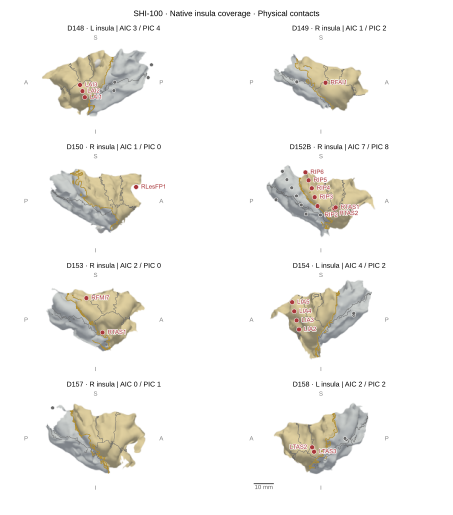

In [5]:
panels, surface_checks, plotted_rows, provenance = [], [], [], []
for subject in SUBJECTS:
    atlas, orig = load_native_atlas(subject)
    subset = contacts[subject].loc[contacts[subject].roi.isin(['AIC', 'PIC'])].copy()
    display_sides = set(subset.recon_hemi) if not subset.empty else set(contacts[subject].recon_hemi)
    assert subset.hemi.eq(subset.recon_hemi).all(), f'{subject}: hemisphere mismatch'
    for hemi, side in [('lh', 'L'), ('rh', 'R')]:
        df = subset.loc[subset.recon_hemi.eq(side)].reset_index(drop=True)
        if side not in display_sides:
            continue
        surface = prepare_surface(subject, hemi, atlas, orig)
        panel = render_panel(subject, hemi, surface, df)
        panels.append(panel)
        mapped = np.isin(surface['labels'], surface['hemi_ids'])
        surface_checks.append(dict(
            subject=subject, hemi=hemi, n_vertices=len(mapped),
            directly_labeled=int(surface['direct'].sum()),
            filled_for_display=int((mapped & ~surface['direct']).sum()),
            unmapped=int((~mapped).sum()),
            max_fill_mm=float(surface['fill_distance'][mapped].max()),
            n_aic=int(df.roi.eq('AIC').sum()), n_pic=int(df.roi.eq('PIC').sum()),
            aic_names=';'.join(df.loc[df.roi.eq('AIC'), 'contact'])))
        table = df.copy()
        table[['display_x_pixel', 'display_y_pixel']] = panel['xy']
        table['display_method'] = 'native orthographic lateral; no contact snapping'
        plotted_rows.append(table)
        paths = [CONTACT_FILES[subject], RECON / subject / 'mri/orig.mgz',
                 surface['pial_path'], surface['annot_path']]
        atlas_dir = MAPER / MAPER_IDS[subject] / 'output'
        paths += [atlas_dir / f'f30-seg95-{MAPER_IDS[subject]}{suffix}.nii.gz'
                  for suffix in ('', '-tc3crisp')]
        provenance.extend(dict(subject=subject, path=str(p), sha256=sha256(p)) for p in paths)
        fig, ax = plt.subplots(figsize=tuple(v * cm for v in SINGLE_SIZE_CM))
        fig.subplots_adjust(bottom=0.05, top=0.90, left=0.025, right=0.975)
        draw_panel(ax, panel)
        path = OUT / f'{subject}_{hemi}_insula_contacts.svg'
        save_sized_svg(fig, path, SINGLE_SIZE_CM)
        plt.close(fig)
        print(f'Saved {path.name}', flush=True)
    del atlas

nrows = int(np.ceil(len(panels) / OVERVIEW_COLUMNS))
overview_size_cm = (OVERVIEW_WIDTH_CM, nrows * PANEL_HEIGHT_CM + 1.4)
fig, axes = plt.subplots(nrows, OVERVIEW_COLUMNS,
                         figsize=tuple(v * cm for v in overview_size_cm), squeeze=False)
fig.subplots_adjust(left=0.025, right=0.975, top=0.935, bottom=0.045, hspace=0.16, wspace=0.10)
for index, (ax, panel) in enumerate(zip(axes.flat, panels)):
    draw_panel(ax, panel, show_scale=(index == len(panels) - 1))
for ax in list(axes.flat)[len(panels):]:
    ax.axis('off')
fig.suptitle('SHI-100 · Native insula coverage · Physical contacts', fontsize=8, y=0.98)
overview = OUT / 'shi100_insula_contacts_overview.svg'
save_sized_svg(fig, overview, overview_size_cm)
plt.close(fig)

checks = pd.DataFrame(surface_checks)
plotted = pd.concat(plotted_rows, ignore_index=True)
assert plotted[['recon_subject', 'contact']].duplicated().sum() == 0
assert plotted.roi.eq('AIC').sum() == selected_summary.n_aic.sum()
assert plotted.roi.eq('PIC').sum() == selected_summary.n_pic.sum()
checks.to_csv(OUT / 'surface_display_qc.csv', index=False)
plotted.to_csv(OUT / 'plotted_contacts.csv', index=False)
selected_summary.to_csv(OUT / 'selected_subjects.csv')
(OUT / 'provenance.json').write_text(json.dumps(dict(
    created_utc=datetime.now(timezone.utc).isoformat(),
    subjects=SUBJECTS, maper_ids={s: MAPER_IDS[s] for s in SUBJECTS},
    coordinates='native FreeSurfer tkRAS mm; no snapping; orthographic projection',
    surface_outline='Destrieux insula only',
    surface_labels='GM-gated Hammers; nearest insula GM fill for display only',
    surface_fill_max_mm=SURFACE_FILL_MAX_MM,
    figure_sizes_cm={'single': SINGLE_SIZE_CM, 'overview': overview_size_cm},
    base_font_pt=fontsize, font_family='Arial', font_path=ARIAL_PATH,
    annotation_style='AIC names adjacent to contacts, no leaders or gyrus abbreviations',
    legend=False, overview_scale_bars=1,
    upstream_sha256=sha256(UPSTREAM), inputs=provenance,
    status='visualization_generated; MRI slice QC and task availability not established'), indent=2))
display(checks)
print(f'Validated {len(plotted)} plotted insula contacts; {plotted.roi.eq("AIC").sum()} AIC.')
display(SVG(filename=str(overview)))

## 5. 查看单例与 AIC 名单

可以在下面替换 `VIEW_SUBJECT`，查看保存的单例 SVG。更改 SUBJECTS、配色或相机参数后，
重新执行上面的生成单元。图仅支持解剖候选筛查；通过切片确认、task 电极匹配及 bipolar 定义后，
再决定最终分析通道。

,contact,atlas_label,roi,x,y,z


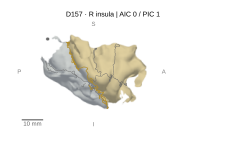

In [6]:
VIEW_SUBJECT = 'D157'
display(plotted.loc[(plotted.recon_subject == VIEW_SUBJECT) & plotted.roi.eq('AIC'),
                    ['contact', 'atlas_label', 'roi', 'x', 'y', 'z']])
for path in sorted(OUT.glob(f'{VIEW_SUBJECT}_*_insula_contacts.svg')):
    display(SVG(filename=str(path)))

## 6. D157 / D158 的边界核查（2026-10-06）

- D157：198 个触点中未检出 AIC（PIC 1 个）；相邻触点中点也未检出 AIC。
  RFAI-ANT11 距最近的同侧 AIC 灰质体素中心约 0.89 mm，属于需要保留复核的边界情况。
  该距离不是到解剖边界的距离，不能据此直接排除病例。
- D158：186 个触点中有 2 个左侧 AIC 触点（LTAS2、LTAS3），均为 Hammers posterior short gyrus；
  LTAS2–LTAS3 中点同样属于 AIC。PIC 2 个。相邻组合仅为解剖候选，尚未建立 task montage 或处理信号。

[原生 MRI 三方向切片](../img/misc/shi100_insula_contacts/late_native_qc/D157_D158_native_aic_qc.svg) ·
[D157 邻近触点记录](../img/misc/shi100_insula_contacts/late_native_qc/D157_aic_distance_qc.csv) ·
[D157 相邻组合](../img/misc/shi100_insula_contacts/late_native_qc/D157_adjacent_pair_anatomy_qc.csv) ·
[D158 相邻组合](../img/misc/shi100_insula_contacts/late_native_qc/D158_adjacent_pair_anatomy_qc.csv)
